# Transformers from Scratch

**Words you need first**
- **Token** = one word of a sentence. **Vector** = a list of numbers describing one token. **Matrix** = a table of numbers (a sentence = one row per token).
- **Dot product** = multiply two lists pairwise, then add. `(1,2)·(2,1) = 1×2 + 2×1 = 4`. Big = "similar".
- **Softmax** = turns scores into percentages that add up to 1.
- **Shape** = size of a table, e.g. `(3, 4)` = 3 rows, 4 columns. Always check shapes!

In [ ]:
import numpy as np                 # numbers and matrices
import matplotlib.pyplot as plt    # drawing pictures
import time                        # measuring speed (Question 10)

np.set_printoptions(precision=3, suppress=True)   # print numbers nicely (3 decimals)
rng = np.random.default_rng(0)                    # random numbers (same every run)

## Question 1 — Positional Encoding: "Which position am I?"

**Problem:** attention can't tell word order ("dog bites man" = "man bites dog").
**Fix:** give each position a unique number pattern made from sine/cosine waves, like clock hands (seconds = fast wave, hours = slow wave).

- `pos` = position of the token (0, 1, 2, …)
- `i` = which pair of dimensions (dimension `2i` gets sin, `2i+1` gets cos)
- `d` = size of the vector, `10000` = constant that makes the slowest wave very slow

Speed of pair `i` = `1 / 10000^(2i/d)`. Pair 0 is fastest (speed 1); later pairs get slower and slower.

In [ ]:
def sinusoidal_positional_encoding(seq_len, d_model):
    """Return an array of shape (seq_len, d_model)."""
    pe = np.zeros((seq_len, d_model))                 # empty table to fill
    for pos in range(seq_len):                        # for each position (row)
        for i in range(d_model // 2):                 # for each pair of columns
            speed = 1.0 / (10000 ** (2 * i / d_model))   # wave speed for this pair
            pe[pos, 2 * i]     = np.sin(pos * speed)     # even column -> sine
            pe[pos, 2 * i + 1] = np.cos(pos * speed)     # odd column  -> cosine
    return pe

# (b) d = 4, positions 0,1,2  -> compare with hand calculation
pe4 = sinusoidal_positional_encoding(3, 4)
print(pe4)
by_hand = np.array([[0, 1, 0, 1],
                    [np.sin(1), np.cos(1), np.sin(0.01), np.cos(0.01)],
                    [np.sin(2), np.cos(2), np.sin(0.02), np.cos(0.02)]])
print("Matches hand calculation:", np.allclose(pe4, by_hand))

[[ 0.     1.     0.     1.   ]
 [ 0.841  0.54   0.01   1.   ]
 [ 0.909 -0.416  0.02   1.   ]]
Matches hand calculation: True


shape: (20, 16)


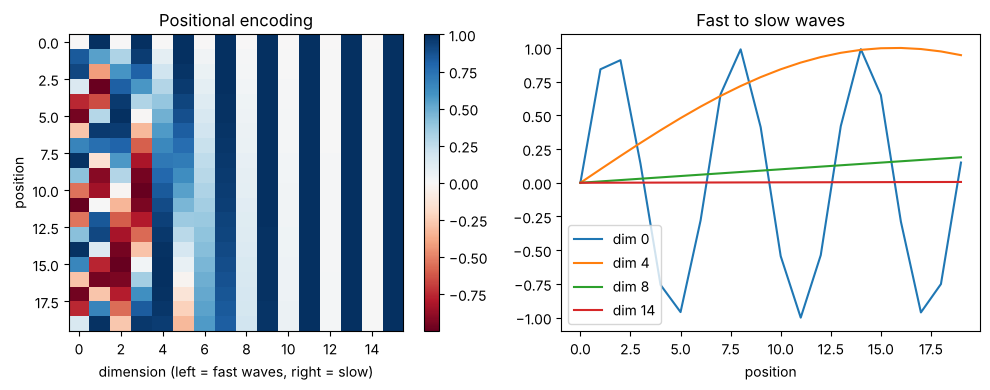

In [ ]:
# (c) seq_len = 20, d_model = 16 and a picture
pe = sinusoidal_positional_encoding(20, 16)
print("shape:", pe.shape)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(pe, cmap="RdBu", aspect="auto")     # colours show the numbers
plt.xlabel("dimension (left = fast waves, right = slow)"); plt.ylabel("position"); plt.title("Positional encoding")
plt.colorbar()
plt.subplot(1, 2, 2)
for dim in [0, 4, 8, 14]:                      # draw a few columns as lines
    plt.plot(pe[:, dim], label=f"dim {dim}")
plt.xlabel("position"); plt.legend(); plt.title("Fast to slow waves")
plt.tight_layout(); plt.show()

**(d) Meaning:** waves repeat (periodic). Fast waves tell neighbouring positions apart; slow waves tell far-apart positions apart. Moving `k` steps is a fixed rotation of each sin/cos pair, so the model can learn "3 words earlier" with simple maths.

## Question 2 — Scaled Dot-Product Attention (the heart of the Transformer)

Each token has a **Query** ("what am I looking for?"), a **Key** ("my label") and a **Value** ("my content").

**Attention = softmax( Q·Kᵀ / √d_k ) · V**

Four steps: ① compare every query with every key (`Q·Kᵀ`, shape `n × n`) → ② divide by `√d_k` so scores don't get huge → ③ softmax each row into percentages → ④ blend the values using those percentages.

*Why `√d_k`?* A dot product of two long vectors is large (it grows like `√d_k`). Large scores make softmax all-or-nothing and the learning signal vanishes.

In [ ]:
def softmax(x):
    """Turn each ROW of scores into percentages that add to 1."""
    x = x - np.max(x, axis=-1, keepdims=True)       # subtract the biggest (avoids overflow, see Q7)
    e = np.exp(x)                                    # e^score (always positive)
    return e / np.sum(e, axis=-1, keepdims=True)    # divide by the row total

def scaled_dot_product_attention(Q, K, V):
    """Q:(n_queries,d_k)  K:(n_keys,d_k)  V:(n_keys,d_v) -> output, weights"""
    d_k = Q.shape[-1]
    scores = Q @ K.T                  # step 1: compare (n_queries, n_keys)
    scores = scores / np.sqrt(d_k)    # step 2: shrink
    weights = softmax(scores)         # step 3: percentages, each row sums to 1
    output = weights @ V              # step 4: blend the values
    return output, weights

# (b) hand example: Q = K = V = identity
Q = K = V = np.array([[1., 0.], [0., 1.]])
print("Q K^T:\n", Q @ K.T)
print("scaled (÷1.414):\n", Q @ K.T / np.sqrt(2))
out, w = scaled_dot_product_attention(Q, K, V)
print("weights:\n", w)
print("output:\n", out)

# (d) checks
print("Each row sums to 1:", w.sum(axis=1))
print("Matches hand answer [[0.670,0.330],[0.330,0.670]]:", np.allclose(out, [[0.670, 0.330], [0.330, 0.670]], atol=1e-3))

Q K^T:
 [[1. 0.]
 [0. 1.]]
scaled (÷1.414):
 [[0.707 0.   ]
 [0.    0.707]]
weights:
 [[0.67 0.33]
 [0.33 0.67]]
output:
 [[0.67 0.33]
 [0.33 0.67]]
Each row sums to 1: [1. 1.]
Matches hand answer [[0.670,0.330],[0.330,0.670]]: True


**Reading the answer:** token 1 pays about 67 % attention to itself and 33 % to token 2.

## Question 3 — Learned Projections (W_Q, W_K, W_V)

Instead of using the token vectors `X` directly, the model multiplies them by three **learned** matrices: `Q = X·W_Q`, `K = X·W_K`, `V = X·W_V`.
Shapes: `X` is `(n, d_model)`; `W_Q, W_K` are `(d_model, d_k)`; `W_V` is `(d_model, d_v)`.
They differ because the jobs differ (what to ask / how to be found / what to give), which lets "A looks at B" be different from "B looks at A".

In [ ]:
def self_attention(X, W_Q, W_K, W_V):
    """Make Q, K, V from X, then run attention. Returns output, weights, (Q,K,V)."""
    Q = X @ W_Q                       # (n, d_k)
    K = X @ W_K                       # (n, d_k)
    V = X @ W_V                       # (n, d_v)
    out, weights = scaled_dot_product_attention(Q, K, V)
    return out, weights, (Q, K, V)

X   = np.array([[1., 2.], [0., 1.]])
W_Q = np.array([[1., 0.], [0., 1.]])      # keeps X as is
W_K = np.array([[0., 1.], [1., 0.]])      # swaps the two columns
W_V = np.array([[2., 0.], [0., 1.]])      # doubles column 1

out, w, (Q, K, V) = self_attention(X, W_Q, W_K, W_V)
print("Q:\n", Q, "\nK:\n", K, "\nV:\n", V)
print("scores Q K^T:\n", Q @ K.T)
print("weights:\n", w)
print("output:\n", out)

# (d) compare with identity projections
I = np.eye(2)
out_id, w_id, _ = self_attention(X, I, I, I)
print("\nIdentity projections -> scores X X^T:\n", X @ X.T)
print("Identity projections -> weights:\n", w_id, "(same weights here - a coincidence!)")
print("Identity projections -> output:\n", out_id, "(different output because of W_V)")

Q:
 [[1. 2.]
 [0. 1.]] 
K:
 [[2. 1.]
 [1. 0.]] 
V:
 [[2. 2.]
 [0. 1.]]
scores Q K^T:
 [[4. 1.]
 [1. 0.]]
weights:
 [[0.893 0.107]
 [0.67  0.33 ]]
output:
 [[1.786 1.893]
 [1.34  1.67 ]]

Identity projections -> scores X X^T:
 [[5. 2.]
 [2. 1.]]
Identity projections -> weights:
 [[0.893 0.107]
 [0.67  0.33 ]] (same weights here - a coincidence!)
Identity projections -> output:
 [[0.893 1.893]
 [0.67  1.67 ]] (different output because of W_V)


**(d) Analysis:** with identity matrices the scores are raw similarity `[[5,2],[2,1]]`; with the given matrices they are `[[4,1],[1,0]]` (the column swap in `W_K` changes who matches whom). Softmax only cares about the **differences inside each row** (5−2 = 4−1 = 3 and 2−1 = 1−0 = 1), so in *this* example both give the same weights `[[0.893, 0.107], [0.670, 0.330]]` — a coincidence. The **outputs still differ** because `W_V` doubles value-feature 1: identity gives `[[0.893, 1.893], [0.670, 1.670]]`, the given matrices give `[[1.786, 1.893], [1.340, 1.670]]`. In general, different projections change both the weights (who attends to whom) and the content that is passed on, so token relationships are learned rather than fixed by raw embeddings.

## Question 4 — Causal Masking: "No peeking at the future"

When generating text, a word can only use words **before** it. In training we see the whole sentence, so we hide the future by adding **−∞** to the scores of future tokens. Since `e^(−∞) = 0`, they get exactly 0 % attention.

A **padding mask** is different: it hides fake `<pad>` filler tokens (used to make sentences equal length), based on the data, not on position.

In [ ]:
def make_causal_mask(n):
    """0 where looking is allowed, -inf where it is forbidden (future)."""
    mask = np.zeros((n, n))
    for i in range(n):                 # row i = token i
        for j in range(n):             # column j = token j
            if j > i:                  # j is in the future of i
                mask[i, j] = -np.inf
    return mask

def causal_self_attention(Q, K, V):
    n, d_k = Q.shape
    scores = Q @ K.T / np.sqrt(d_k)    # normal scores
    scores = scores + make_causal_mask(n)   # block the future
    weights = softmax(scores)          # blocked entries become 0
    return weights @ V, weights

print("4x4 mask:\n", make_causal_mask(4))

Q = K = V = np.array([[1., 0.], [0., 1.], [1., 1.]])
print("\nscaled scores:\n", Q @ K.T / np.sqrt(2))
out, w = causal_self_attention(Q, K, V)
print("weights:\n", w)
print("output:\n", out)

# (d) verify: everything above the diagonal is zero
print("Future weights all zero:", np.all(np.triu(w, k=1) == 0))
print("Token 1 probs:", w[0], "| Token 2 probs:", w[1])

4x4 mask:
 [[  0. -inf -inf -inf]
 [  0.   0. -inf -inf]
 [  0.   0.   0. -inf]
 [  0.   0.   0.   0.]]

scaled scores:
 [[0.707 0.    0.707]
 [0.    0.707 0.707]
 [0.707 0.707 1.414]]
weights:
 [[1.    0.    0.   ]
 [0.33  0.67  0.   ]
 [0.248 0.248 0.503]]
output:
 [[1.    0.   ]
 [0.33  0.67 ]
 [0.752 0.752]]
Future weights all zero: True
Token 1 probs: [1. 0. 0.] | Token 2 probs: [0.33 0.67 0.  ]


## Question 5 — Cross-Attention (used in translation)

In self-attention Q, K, V all come from one sequence. In **cross-attention** the **Query comes from the decoder** (the sentence being written) while **Key and Value come from the encoder** (the source sentence).
With `n` decoder tokens and `m` encoder tokens the score table is `n × m` — not necessarily square.

In [ ]:
def cross_attention(decoder_states, encoder_states, W_Q, W_K, W_V):
    Q = decoder_states @ W_Q      # (n, d_k)   questions from the decoder
    K = encoder_states @ W_K      # (m, d_k)   labels from the encoder
    V = encoder_states @ W_V      # (m, d_v)   content from the encoder
    return scaled_dot_product_attention(Q, K, V)

# (b) hand example (K and V are given separately, so use attention directly)
Q = np.array([[1., 0.]])
K = np.array([[1., 0.], [0., 1.], [1., 1.]])
V = np.array([[2., 0.], [0., 2.], [1., 1.]])
print("scaled scores:", Q @ K.T / np.sqrt(2))
out, w = scaled_dot_product_attention(Q, K, V)
print("weights:", w, "-> sum", w.sum())
print("output:", out)

# (c) shape demo: 3 decoder tokens, 5 encoder tokens, d_model = 8
dec, enc = rng.normal(size=(3, 8)), rng.normal(size=(5, 8))
Wq, Wk, Wv = [rng.normal(scale=0.3, size=(8, 8)) for _ in range(3)]
o, a = cross_attention(dec, enc, Wq, Wk, Wv)
print("\noutput shape:", o.shape, "| weights shape:", a.shape, "(3 x 5: not square!)")

scaled scores: [[0.707 0.    0.707]]
weights: [[0.401 0.198 0.401]] -> sum 1.0
output: [[1.203 0.797]]

output shape: (3, 8) | weights shape: (3, 5) (3 x 5: not square!)


**(d) Meaning:** each decoder token asks the source sentence "which part do I need now?"; the weights show where it looks. The table is `n × m` because target and source can have different lengths.

## Question 6 — Multi-Head Attention

One attention pattern can't catch everything, so we run **H** smaller attentions ("heads") side by side, then glue (concatenate) the results and mix them with `W_O`.
With `d_model = 8`, `H = 2`: each head uses `d_k = 8/2 = 4`. Shapes: per-head `W` is `8×4`, head output `n×4`, concatenated `n×8`, `W_O` is `8×8`, final `n×8`.

In [ ]:
def multi_head_attention(X, W_Q, W_K, W_V, W_O, num_heads, causal=False, X_kv=None):
    """X:(n,d_model). W's:(d_model,d_model). Returns output (n,d_model) and weights (H,n,n_keys).
    causal=True hides the future; X_kv lets keys/values come from another sequence (cross-attention)."""
    if X_kv is None:
        X_kv = X                                    # self-attention: same sequence
    n, d_model = X.shape
    d_k = d_model // num_heads                      # size of each head
    Q, K, V = X @ W_Q, X_kv @ W_K, X_kv @ W_V       # project, all (., d_model)

    head_outputs, all_weights = [], []
    for h in range(num_heads):                      # each head looks at its own slice of columns
        cols = slice(h * d_k, (h + 1) * d_k)        # e.g. head 0 -> columns 0..3
        scores = Q[:, cols] @ K[:, cols].T / np.sqrt(d_k)
        if causal:
            scores = scores + make_causal_mask(n)   # hide the future
        weights = softmax(scores)                   # (n, n_keys)
        head_outputs.append(weights @ V[:, cols])   # (n, d_k)
        all_weights.append(weights)

    concat = np.concatenate(head_outputs, axis=1)   # glue heads side by side -> (n, d_model)
    return concat @ W_O, np.array(all_weights)      # mix with W_O

# (b) hand example with explicit per-head matrices
X = np.eye(2)
swap = np.array([[0., 1.], [1., 0.]])
head1, w1 = scaled_dot_product_attention(X, X, X)                 # all identity
head2, w2 = scaled_dot_product_attention(X @ swap, X @ swap, X)   # Q=K=swapped, V=identity
print("head 1 weights:\n", w1, "\nhead 1 output:\n", head1)
print("head 2 weights:\n", w2, "\nhead 2 output:\n", head2)
print("concatenated (2x4):\n", np.concatenate([head1, head2], axis=1))

# (c) real test: n = 4 tokens, d_model = 8, 2 heads
X = rng.normal(size=(4, 8))
Wq, Wk, Wv, Wo = [rng.normal(scale=0.3, size=(8, 8)) for _ in range(4)]
out, w = multi_head_attention(X, Wq, Wk, Wv, Wo, num_heads=2)
print("\noutput shape:", out.shape, "| weights shape:", w.shape, "(heads, n, n)")
print("rows sum to 1:", np.allclose(w.sum(axis=-1), 1))

head 1 weights:
 [[0.67 0.33]
 [0.33 0.67]] 
head 1 output:
 [[0.67 0.33]
 [0.33 0.67]]
head 2 weights:
 [[0.67 0.33]
 [0.33 0.67]] 
head 2 output:
 [[0.67 0.33]
 [0.33 0.67]]
concatenated (2x4):
 [[0.67 0.33 0.67 0.33]
 [0.33 0.67 0.33 0.67]]

output shape: (4, 8) | weights shape: (2, 4, 4) (heads, n, n)
rows sum to 1: True


**(d) Analysis:** every head has its own matrices, so each can specialise (grammar, nearby words, pronouns…). More heads ≠ more power: the total number of parameters stays the same, each head gets narrower, many end up copying each other, and attention-table memory grows with `H`.

## Question 7 — Numerical Stability and Temperature

**(a) Proof** that `softmax(z) = softmax(z − max z)`: let `c = max z`. Then `e^(z−c) = e^z · e^(−c)`. The factor `e^(−c)` appears in every term on top **and** in every term of the sum below, so it cancels. ∎
After subtracting, the biggest exponent is `e^0 = 1`, so nothing overflows.

In [ ]:
def stable_softmax(x, axis=-1):
    """Numerically stable softmax."""
    x = np.asarray(x, dtype=float)
    shifted = x - np.max(x, axis=axis, keepdims=True)    # biggest value becomes 0
    e = np.exp(shifted)
    return e / np.sum(e, axis=axis, keepdims=True)

z = np.array([1000., 1001., 1002.])
with np.errstate(all="ignore"):                          # hide the overflow warning
    broken = np.exp(z) / np.sum(np.exp(z))
print("direct formula :", broken, " <- NaN = broken (e^1000 is too big)")
print("stable softmax :", stable_softmax(z))

direct formula : [nan nan nan]  <- NaN = broken (e^1000 is too big)
stable softmax : [0.09  0.245 0.665]


T=0.5: [0.425 0.    0.015 0.028 0.532]   biggest = 0.53
T=1: [0.387 0.007 0.074 0.099 0.433]   biggest = 0.43
T=2: [0.319 0.042 0.139 0.161 0.338]   biggest = 0.34
T=4: [0.266 0.096 0.176 0.189 0.273]   biggest = 0.27


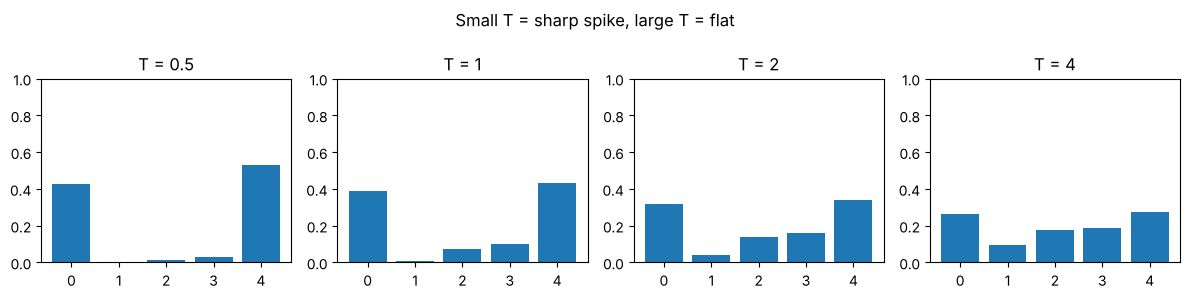

d_k=    4: spread of q.k =    2.0  (sqrt(d_k) =   2.0)  after dividing: 1.01
d_k=   64: spread of q.k =    8.0  (sqrt(d_k) =   8.0)  after dividing: 1.00
d_k= 1024: spread of q.k =   32.3  (sqrt(d_k) =  32.0)  after dividing: 1.01
logits x  1: biggest prob = 0.418, gradient size = 0.4063
logits x100: biggest prob = 1.000, gradient size = 0.0000


In [ ]:
# (c) Temperature: divide the scores by T before softmax
scores = rng.normal(size=(1, 5)) * 2        # 5 scores for one query
temps = [0.5, 1, 2, 4]
plt.figure(figsize=(12, 3))
for k, T in enumerate(temps):
    p = stable_softmax(scores / T)[0]
    print(f"T={T}: {p}   biggest = {p.max():.2f}")
    plt.subplot(1, 4, k + 1); plt.bar(range(5), p); plt.ylim(0, 1); plt.title(f"T = {T}")
plt.suptitle("Small T = sharp spike, large T = flat"); plt.tight_layout(); plt.show()

# Why sqrt(d_k)? dot products get bigger as vectors get longer
for d_k in [4, 64, 1024]:
    q, k = rng.normal(size=(2000, d_k)), rng.normal(size=(2000, d_k))
    dots = (q * k).sum(axis=1)
    print(f"d_k={d_k:5d}: spread of q.k = {dots.std():6.1f}  (sqrt(d_k) = {np.sqrt(d_k):5.1f})  after dividing: {(dots/np.sqrt(d_k)).std():.2f}")

# Gradient: softmax slope = p_i (delta_ij - p_j). If p is almost one-hot, the slope is ~0
def softmax_slope_size(p):
    jac = np.diag(p) - np.outer(p, p)
    return np.linalg.norm(jac)
z = rng.normal(size=6)
for scale in [1, 100]:
    p = stable_softmax(z * scale)
    print(f"logits x{scale:3d}: biggest prob = {p.max():.3f}, gradient size = {softmax_slope_size(p):.4f}")

**(d) Explanation:** low temperature = confident spike; high = flat. Dividing by `√d_k` is a built-in temperature that stops long vectors from creating huge scores. When one probability is ≈ 1 the gradient is ≈ 0 (see the last lines above), so the model stops learning — the **vanishing gradient** problem.

## Question 8 — Encoder Block

```
X → Multi-Head Attention → (+X) → LayerNorm → H → Feed-Forward → (+H) → LayerNorm → Y
```
- **Attention** lets tokens exchange information. **FFN** = small 2-layer network applied to each token separately (expand to `d_ff`, ReLU, shrink back).
- **Residual (+X):** output = input + change; keeps the original and helps learning signals flow back.
- **LayerNorm:** for each token, shift its numbers to average 0 and spread 1, then scale by `gamma` and shift by `beta`.

In [ ]:
def layer_norm(X, gamma, beta, eps=1e-5):
    mean = X.mean(axis=-1, keepdims=True)       # average of each token's numbers
    var = X.var(axis=-1, keepdims=True)         # spread of each token's numbers
    X_norm = (X - mean) / np.sqrt(var + eps)    # average 0, spread 1 (eps avoids dividing by 0)
    return gamma * X_norm + beta                # learned scale and shift

def feed_forward(X, W1, b1, W2, b2):
    hidden = np.maximum(0, X @ W1 + b1)         # expand (d_model -> d_ff) then ReLU (negatives -> 0)
    return hidden @ W2 + b2                     # shrink back (d_ff -> d_model)

def transformer_encoder_block(X, params):
    p = params
    attn, _ = multi_head_attention(X, p["W_Q"], p["W_K"], p["W_V"], p["W_O"], p["num_heads"])
    H = layer_norm(X + attn, p["gamma1"], p["beta1"])                   # residual + norm
    ffn = feed_forward(H, p["W1"], p["b1"], p["W2"], p["b2"])
    return layer_norm(H + ffn, p["gamma2"], p["beta2"])                 # residual + norm

def init_encoder_params(d_model, d_ff):
    g = lambda *shape: rng.normal(scale=0.3, size=shape)                # small random weights
    return dict(W_Q=g(d_model, d_model), W_K=g(d_model, d_model), W_V=g(d_model, d_model), W_O=g(d_model, d_model),
                W1=g(d_model, d_ff), b1=np.zeros(d_ff), W2=g(d_ff, d_model), b2=np.zeros(d_model),
                gamma1=np.ones(d_model), beta1=np.zeros(d_model), gamma2=np.ones(d_model), beta2=np.zeros(d_model),
                num_heads=2)

X = rng.normal(size=(6, 8))                     # 6 tokens, d_model = 8
params = init_encoder_params(8, 16)
Y = transformer_encoder_block(X, params)
print("input shape", X.shape, "-> output shape", Y.shape)
print("each token has average ~0:", np.allclose(Y.mean(axis=-1), 0, atol=1e-6))
print("each token has spread  ~1:", np.allclose(Y.var(axis=-1), 1, atol=1e-3))

# FFN works on each token alone: row 2 alone gives the same answer as row 2 inside the full table
full = feed_forward(X, params["W1"], params["b1"], params["W2"], params["b2"])
alone = feed_forward(X[[2]], params["W1"], params["b1"], params["W2"], params["b2"])
print("FFN treats tokens independently:", np.allclose(full[[2]], alone))

input shape (6, 8) -> output shape (6, 8)
each token has average ~0: True
each token has spread  ~1: True
FFN treats tokens independently: True


**(c) Analysis:** the FFN uses the same weights on every token separately, so token `i`'s result depends only on token `i`. Attention output for token `i` is a blend of **all** tokens, so attention is the only place tokens talk to each other. The residual shortcut has derivative `1 + dF/dx`; the "1" gives gradients a straight path, so deep stacks still train.

## Question 9 — Decoder Block and the Whole Transformer

**Whole model:** source words → embedding + positional encoding → N encoder blocks → *memory*. Target words (shifted right) → embedding + positions → N decoder blocks (which read the memory) → linear layer to vocabulary size → softmax → next-word probabilities.

**Decoder block, 3 parts, each followed by Add & Norm:**
1. **Masked self-attention** — looks only at earlier target words.
2. **Cross-attention** — Q from the decoder, K and V from the encoder memory.
3. **Feed-forward network.**

The decoder needs the causal mask (future words don't exist while generating); the encoder doesn't (the whole source sentence is already known).

In [ ]:
def transformer_decoder_block(decoder_input, encoder_output, params):
    p = params; H = p["num_heads"]
    sa, ca = p["self_attn"], p["cross_attn"]
    # 1) masked self-attention + residual + norm
    a1, _ = multi_head_attention(decoder_input, sa["W_Q"], sa["W_K"], sa["W_V"], sa["W_O"], H, causal=True)
    x1 = layer_norm(decoder_input + a1, p["gamma1"], p["beta1"])         # (n, d_model)
    # 2) cross-attention (keys/values from the encoder) + residual + norm
    a2, w_cross = multi_head_attention(x1, ca["W_Q"], ca["W_K"], ca["W_V"], ca["W_O"], H, X_kv=encoder_output)
    x2 = layer_norm(x1 + a2, p["gamma2"], p["beta2"])                    # (n, d_model)
    # 3) feed-forward + residual + norm
    f = feed_forward(x2, p["W1"], p["b1"], p["W2"], p["b2"])
    return layer_norm(x2 + f, p["gamma3"], p["beta3"]), w_cross          # (n, d_model)

def init_decoder_params(d_model, d_ff, num_heads=2):
    g = lambda *shape: rng.normal(scale=0.3, size=shape)
    attn = lambda: dict(W_Q=g(d_model, d_model), W_K=g(d_model, d_model), W_V=g(d_model, d_model), W_O=g(d_model, d_model))
    one, zero = np.ones(d_model), np.zeros(d_model)
    return dict(self_attn=attn(), cross_attn=attn(), num_heads=num_heads,
                W1=g(d_model, d_ff), b1=np.zeros(d_ff), W2=g(d_ff, d_model), b2=zero.copy(),
                gamma1=one, beta1=zero, gamma2=one, beta2=zero, gamma3=one, beta3=zero)

# d_model = 8, 2 heads, encoder length 5, decoder length 3
enc_out = rng.normal(size=(5, 8))
dec_in  = rng.normal(size=(3, 8))
dp = init_decoder_params(8, 16)
out, w_cross = transformer_decoder_block(dec_in, enc_out, dp)

print("encoder output :", enc_out.shape, "(5 x 8)")
print("decoder input  :", dec_in.shape, "(3 x 8)")
print("cross weights  :", w_cross.shape, "(2 heads x 3 decoder x 5 encoder)")
print("decoder output :", out.shape, "(3 x 8)")
assert out.shape == (3, 8) and w_cross.shape == (2, 3, 5)

# Causal test: changing the LAST decoder token must not change earlier outputs
dec2 = dec_in.copy(); dec2[2] += 5
out2, _ = transformer_decoder_block(dec2, enc_out, dp)
print("tokens 1-2 unchanged when token 3 changes:", np.allclose(out[:2], out2[:2]))

encoder output : (5, 8) (5 x 8)
decoder input  : (3, 8) (3 x 8)
cross weights  : (2, 3, 5) (2 heads x 3 decoder x 5 encoder)
decoder output : (3, 8) (3 x 8)
tokens 1-2 unchanged when token 3 changes: True


**(c) Information flow:** the encoder reads the source (every word sees every word) and produces memory. Each decoder word first gathers context from earlier target words, then looks into the memory to fetch the source facts it needs, then refines the result with the FFN. A final linear + softmax turns it into next-word probabilities.

## Question 10 — Computational Cost

`n` = tokens, `d` = d_model, `H` = heads, `d_k = d/H`. Counting multiply-adds:

| Step | Cost (all heads) |
|---|---|
| Q, K, V projections | `3 n d²` |
| `Q·Kᵀ` | `n² d` (per head `n² d_k`) |
| weights `·V` | `n² d` |
| output projection | `n d²` |
| **Total** | **O(n d² + n² d)** |
| attention-table memory | `H n²` numbers (`8 H n²` bytes) |

Per head things are `H` times smaller, but summed over heads the main cost does not depend on `H`; only memory and softmax work grow with `H`.

n=  32 | time =    0.175 ms | attention memory =     32.0 KiB
n=  64 | time =    0.238 ms | attention memory =    128.0 KiB
n= 128 | time =    0.759 ms | attention memory =    512.0 KiB
n= 256 | time =    2.872 ms | attention memory =   2048.0 KiB


n= 512 | time =   10.319 ms | attention memory =   8192.0 KiB


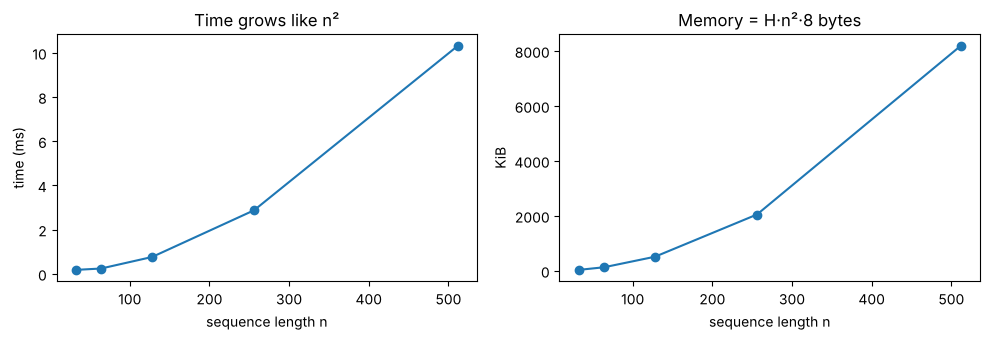

Memory at n=512 vs n=256: 4.0 times bigger (expected 4)


In [ ]:
def benchmark_attention(seq_lengths, d_model, num_heads):
    """Time attention for each length and compute attention-table memory."""
    Wq, Wk, Wv, Wo = [rng.normal(scale=0.1, size=(d_model, d_model)) for _ in range(4)]
    times, memories = [], []
    for n in seq_lengths:
        X = rng.normal(size=(n, d_model))
        multi_head_attention(X, Wq, Wk, Wv, Wo, num_heads)         # warm-up run (not timed)
        runs = []
        for _ in range(5):                                          # time 5 runs, keep the middle one
            start = time.perf_counter()
            multi_head_attention(X, Wq, Wk, Wv, Wo, num_heads)
            runs.append(time.perf_counter() - start)
        t = np.median(runs) * 1000                                  # milliseconds
        mem_kib = num_heads * n * n * 8 / 1024                      # H * n * n numbers, 8 bytes each
        times.append(t); memories.append(mem_kib)
        print(f"n={n:4d} | time = {t:8.3f} ms | attention memory = {mem_kib:8.1f} KiB")
    return times, memories

lengths = [32, 64, 128, 256, 512]
times, memories = benchmark_attention(lengths, d_model=64, num_heads=4)

plt.figure(figsize=(10, 3.5))
plt.subplot(1, 2, 1); plt.plot(lengths, times, "o-"); plt.xlabel("sequence length n"); plt.ylabel("time (ms)"); plt.title("Time grows like n²")
plt.subplot(1, 2, 2); plt.plot(lengths, memories, "o-"); plt.xlabel("sequence length n"); plt.ylabel("KiB"); plt.title("Memory = H·n²·8 bytes")
plt.tight_layout(); plt.show()
print("Memory at n=512 vs n=256:", memories[4] / memories[3], "times bigger (expected 4)")

**(c) Analysis:** every token is compared with every other token, so there are `n²` scores: doubling `n` makes attention about 4× more expensive in time and memory. More heads leave the main arithmetic the same but need more memory. A mask does **not** cut arithmetic in this simple code (the full table is still computed, then masked). Smart implementations (e.g. FlashAttention) skip masked blocks and avoid storing the full table — an *implementation* saving, not a change in the formal cost. Real speed also depends on memory access and optimised libraries, not just counting operations.

